# Urban Expansion in Rawalpindi District (2019-2025): ML Land-Cover Mapping
**Author:** Malaika Noor | **Tools:** Google Earth Engine (Python API), scikit-learn

Everything runs from Earth Engine: no manual sampling and no data downloads.

**Workflow**
1. Sentinel-2 composites (January-April) for 2019, 2021 and 2025, with spectral bands plus NDVI, NDBI and MNDWI.
2. **Classifier benchmark:** Random Forest, Gradient Boosting and SVM trained on ESA WorldCover (2021) labels, tested with random and spatial-block cross-validation.
3. **Change mapping:** a separate Random Forest trained for each year (2019 and 2025) on Dynamic World labels for that year.
4. Area statistics, change and a transition matrix.

**Important note on method:** a first attempt used one classifier trained on 2021 and applied it to 2019 and 2025. It gave an implausible decrease in built-up land, because spectral differences between years were treated as land-cover change. This notebook trains each year separately instead.

In [2]:
!pip -q install earthengine-api scikit-learn pandas matplotlib seaborn
import ee, os, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display

PROJECT = 'ee-nmalaika135'   # your Earth Engine / Google Cloud project id
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT)
os.makedirs('results', exist_ok=True)

## 1. Study area and Sentinel-2 composites (January-April)

In [3]:
gb = ee.FeatureCollection('WM/geoLab/geoBoundaries/600/ADM2').filter(ee.Filter.eq('shapeGroup', 'PAK'))
roi_fc = gb.filter(ee.Filter.eq('shapeName', 'Rawalpindi'))
print('Features found:', roi_fc.size().getInfo())   # should be 1
roi = roi_fc.geometry()
region = roi.bounds()

BANDS_RAW = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']

def mask_scl(img):
    scl = img.select('SCL')
    ok = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return img.updateMask(ok)

def s2_composite(year):
    col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(roi)
           .filterDate(f'{year}-01-01', f'{year}-04-30')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40)).map(mask_scl))
    comp = col.select(BANDS_RAW).median().divide(10000)
    ndvi = comp.normalizedDifference(['B8', 'B4']).rename('NDVI')
    ndbi = comp.normalizedDifference(['B11', 'B8']).rename('NDBI')
    mndwi = comp.normalizedDifference(['B3', 'B11']).rename('MNDWI')
    return comp.addBands([ndvi, ndbi, mndwi]).clip(roi)

FEATS = BANDS_RAW + ['NDVI', 'NDBI', 'MNDWI']
comp = {y: s2_composite(y) for y in (2019, 2021, 2025)}

Features found: 1


## 2. Classifier benchmark
Training labels come from ESA WorldCover 2021, merged into 6 classes: Tree cover, Shrub/Grass, Cropland, Built-up, Bare, Water.
These labels are automatic, so the scores below measure agreement with WorldCover, not true accuracy on the ground.

In [4]:
CLASSES = ['Tree cover', 'Shrub/Grass', 'Cropland', 'Built-up', 'Bare', 'Water']
wc = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
label = wc.remap([10, 20, 30, 40, 50, 60, 80], [0, 1, 1, 2, 3, 4, 5]).rename('label').clip(roi)

stack = comp[2021].select(FEATS).addBands(label)
samples = stack.stratifiedSample(numPoints=600, classBand='label', region=roi, scale=20,
                                 seed=42, geometries=True, tileScale=4)
feats = samples.getInfo()['features']
S = pd.DataFrame([{**f['properties'], 'lon': f['geometry']['coordinates'][0],
                   'lat': f['geometry']['coordinates'][1]} for f in feats]).dropna()
S['label'] = S['label'].astype(int)
print(S.shape); print(S['label'].map(dict(enumerate(CLASSES))).value_counts())

(3600, 16)
label
Tree cover     600
Shrub/Grass    600
Cropland       600
Built-up       600
Bare           600
Water          600
Name: count, dtype: int64


In [5]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

X, y = S[FEATS].values, S['label'].values
# ~5 km spatial blocks: neighbouring pixels always stay in the same fold
blocks = (np.floor(S.lat / 0.05).astype(int).astype(str) + '_' + np.floor(S.lon / 0.05).astype(int).astype(str)).values
print('Spatial blocks:', len(set(blocks)))

models = {
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    'GradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'SVM-RBF': make_pipeline(StandardScaler(), SVC(C=5, class_weight='balanced')),
}
rows, store = [], {}
for name, m in models.items():
    p_rand = cross_val_predict(m, X, y, cv=KFold(5, shuffle=True, random_state=42))
    p_spat = cross_val_predict(m, X, y, cv=GroupKFold(5), groups=blocks)
    store[name] = p_spat
    rows.append(dict(model=name,
                     acc_random_CV=accuracy_score(y, p_rand), F1macro_random_CV=f1_score(y, p_rand, average='macro'),
                     acc_spatial_CV=accuracy_score(y, p_spat), F1macro_spatial_CV=f1_score(y, p_spat, average='macro')))
bench = pd.DataFrame(rows).set_index('model').round(3)
bench['optimism_gap'] = (bench.acc_random_CV - bench.acc_spatial_CV).round(3)
bench.to_csv('results/classifier_benchmark.csv'); bench

Spatial blocks: 271


,acc_random_CV,F1macro_random_CV,acc_spatial_CV,F1macro_spatial_CV,optimism_gap
model,,,,,
RandomForest,0.755,0.755,0.751,0.751,0.004
GradientBoosting,0.751,0.751,0.749,0.750,0.002
SVM-RBF,0.782,0.783,0.779,0.780,0.003


Best (spatial CV): SVM-RBF


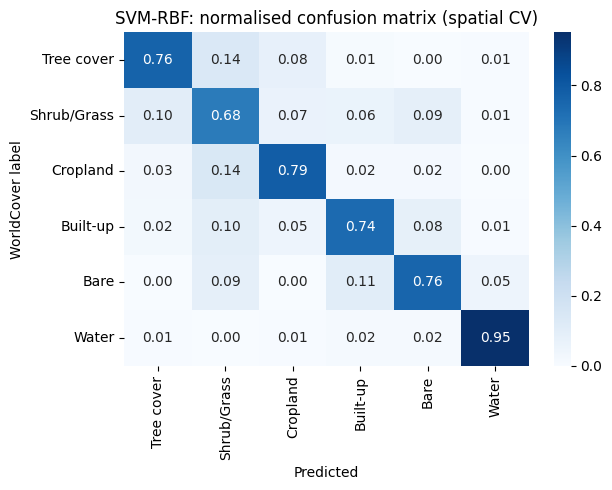

              precision    recall  f1-score   support

  Tree cover       0.83      0.76      0.79       600
 Shrub/Grass       0.59      0.68      0.63       600
    Cropland       0.79      0.79      0.79       600
    Built-up       0.77      0.74      0.76       600
        Bare       0.78      0.76      0.77       600
       Water       0.93      0.95      0.94       600

    accuracy                           0.78      3600
   macro avg       0.78      0.78      0.78      3600
weighted avg       0.78      0.78      0.78      3600



In [6]:
best = bench['F1macro_spatial_CV'].idxmax(); print('Best (spatial CV):', best)
present = sorted(set(y))
cm = confusion_matrix(y, store[best], labels=present, normalize='true')
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=[CLASSES[i] for i in present],
            yticklabels=[CLASSES[i] for i in present])
plt.title(f'{best}: normalised confusion matrix (spatial CV)'); plt.ylabel('WorldCover label'); plt.xlabel('Predicted')
plt.tight_layout(); plt.savefig('results/confusion_matrix.png', dpi=200); plt.show()
print(classification_report(y, store[best], labels=present, target_names=[CLASSES[i] for i in present]))

## 3. Land-cover maps for 2019 and 2025
Each year gets its **own** Random Forest, trained inside Earth Engine on Dynamic World labels from the same months of that year. This keeps the two maps comparable.
Dynamic World classes are merged into the same 6 classes.

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


2019


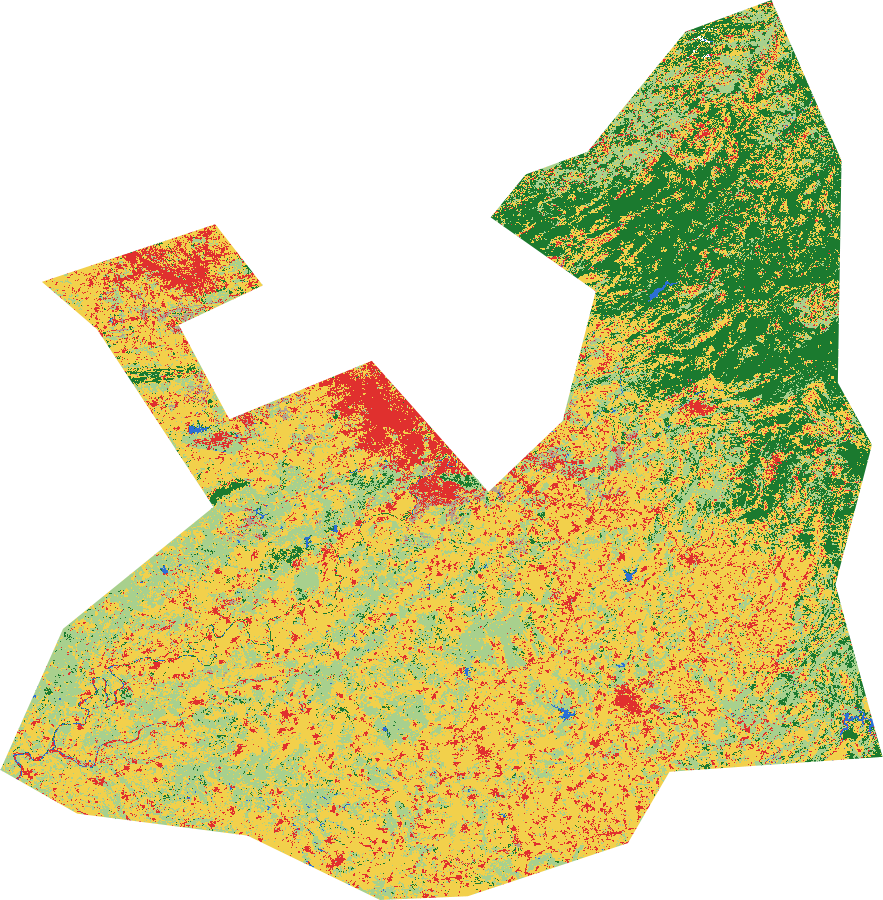

retry 2025 HTTPSConnectionPool(host='earthengine.googleapis.com', port=443): Read timed out. (read timeout=120)
retry 2025 HTTPSConnectionPool(host='earthengine.googleapis.com', port=443): Read timed out. (read timeout=120)
2025


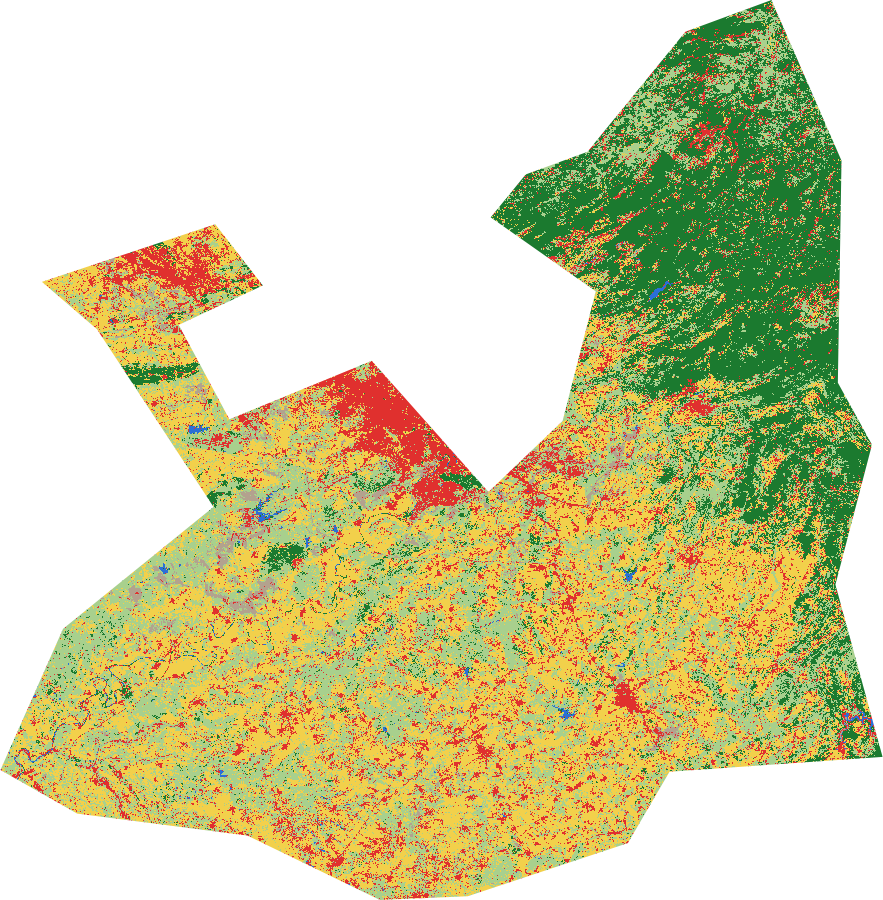

Legend: {'Tree cover': '1b7a2f', 'Shrub/Grass': 'a8d08d', 'Cropland': 'f2d04b', 'Built-up': 'e0302e', 'Bare': 'b3a28e', 'Water': '2b6fd6'}


In [10]:
DW_MAP = {0: 5, 1: 0, 2: 1, 3: 2, 4: 2, 5: 1, 6: 3, 7: 4}
PALETTE = ['1b7a2f', 'a8d08d', 'f2d04b', 'e0302e', 'b3a28e', '2b6fd6']

def year_map(year):
    c = comp[year].select(FEATS)
    dw = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterBounds(roi)
          .filterDate(f'{year}-01-01', f'{year}-04-30').select('label').mode())
    lab = dw.remap(list(DW_MAP.keys()), list(DW_MAP.values())).rename('label').clip(roi)
    s = c.addBands(lab).sample(region=roi, scale=30, numPixels=6000, seed=42, tileScale=4)
    clf_y = ee.Classifier.smileRandomForest(300, seed=42).train(s, 'label', FEATS)
    return c.classify(clf_y).rename('c')

map19 = year_map(2019)
map25 = year_map(2025)

def save_map(m, yr, tries=4):
    for k in range(tries):
        try:
            u = m.visualize(min=0, max=5, palette=PALETTE).getThumbURL({'region': region, 'dimensions': 900, 'format': 'png'})
            r = requests.get(u, timeout=120)
            if r.status_code == 200 and r.headers.get('content-type', '').startswith('image'):
                open(f'results/lulc_{yr}.png', 'wb').write(r.content)
                print(yr); display(Image(r.content)); return
        except Exception as e:
            print('retry', yr, e)
        time.sleep(5)
    print('Could not download the map for', yr, '- re-run this cell')

save_map(map19, 2019); save_map(map25, 2025)
print('Legend:', dict(zip(CLASSES, PALETTE)))

## 4. Area statistics and change

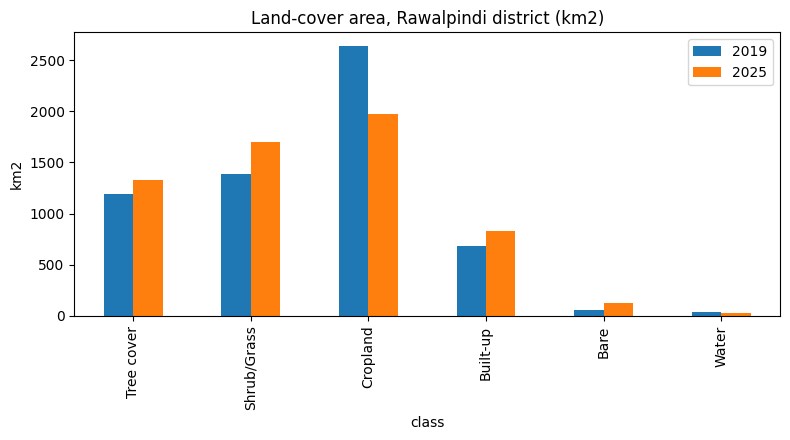

,2019,2025,change_km2,change_%
class,,,,
Tree cover,1188.27,1329.42,141.14,11.88
Shrub/Grass,1390.06,1703.69,313.62,22.56
Cropland,2640.22,1971.09,-669.13,-25.34
Built-up,679.61,827.31,147.70,21.73
Bare,53.80,126.42,72.63,135.00
Water,35.99,30.91,-5.08,-14.12


In [8]:
def class_area(img):
    a = ee.Image.pixelArea().divide(1e6).addBands(img)
    g = a.reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='c'), geometry=roi,
                       scale=30, maxPixels=1e11, bestEffort=True, tileScale=4).get('groups')
    d = pd.DataFrame(ee.List(g).getInfo()).rename(columns={'sum': 'km2'})
    d['class'] = d['c'].astype(int).map(dict(enumerate(CLASSES)))
    return d.set_index('class')['km2']

area = pd.DataFrame({'2019': class_area(map19), '2025': class_area(map25)}).fillna(0)
area['change_km2'] = area['2025'] - area['2019']
area['change_%'] = area['change_km2'] / area['2019'] * 100
area = area.round(2)
area.to_csv('results/area_change.csv')

area[['2019', '2025']].plot.bar(figsize=(8, 4.5), title='Land-cover area, Rawalpindi district (km2)')
plt.ylabel('km2'); plt.tight_layout(); plt.savefig('results/area_change.png', dpi=200); plt.show()
area

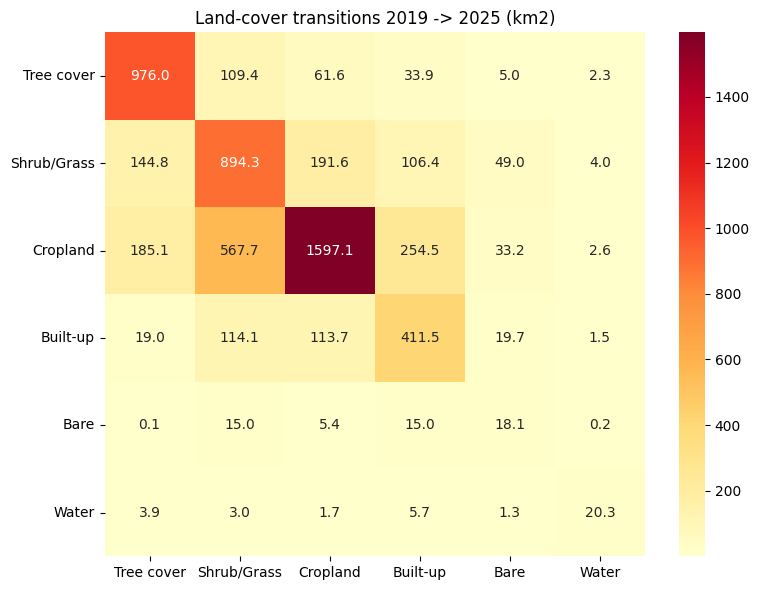

In [9]:
t_img = map19.multiply(10).add(map25).rename('t')
a = ee.Image.pixelArea().divide(1e6).addBands(t_img)
g = a.reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='t'), geometry=roi,
                   scale=30, maxPixels=1e11, bestEffort=True, tileScale=4).get('groups')
T = pd.DataFrame(ee.List(g).getInfo())
T['from'] = (T.t // 10).astype(int); T['to'] = (T.t % 10).astype(int)
tm = T.pivot_table(index='from', columns='to', values='sum', aggfunc='sum').fillna(0)
tm.index = [CLASSES[i] for i in tm.index]; tm.columns = [CLASSES[i] for i in tm.columns]
plt.figure(figsize=(8, 6)); sns.heatmap(tm.round(1), annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Land-cover transitions 2019 -> 2025 (km2)'); plt.tight_layout()
plt.savefig('results/transition_matrix.png', dpi=200); plt.show()
tm.round(2).to_csv('results/transition_matrix.csv')

## 5. Limitations
- Labels are automatic (WorldCover for the benchmark, Dynamic World for the maps) and contain errors; there is no field validation.
- Benchmark scores measure agreement with WorldCover labels, not true accuracy. The final maps were not independently validated, so areas are approximate.
- Changes in cropland and bare land are likely affected by seasonal differences and label noise. The most reliable result is the direction and rough size of built-up growth.
- Only January-April imagery was used.

**Future work:** independent validation points from high-resolution imagery, seasonal composites, deep-learning segmentation, and urban growth projection.